# 06.5 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/06-unsupervised/05-dbscan-gmm/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

In [2]:
names = list("PQRSTUVWXY")
points = np.array([[1, 1], [1, 2], [2, 1], [2, 2], [3, 2],
                   [6, 6], [6, 7], [7, 6], [8, 7], [4, 8]], dtype=float)

In [3]:
from sklearn.cluster import DBSCAN
from scipy.spatial.distance import cdist

def dbscan_table(points, eps, min_samples):
    """Neighbour counts and point kinds, next to DBSCAN's labels."""
    db = DBSCAN(eps=eps, min_samples=min_samples).fit(points)
    core = np.zeros(len(points), bool); core[db.core_sample_indices_] = True
    near = cdist(points, points) <= eps
    kind = np.where(core, "core", np.where(db.labels_ == -1, "noise", "border"))
    return pd.DataFrame({"neighbours": [", ".join(np.array(names)[row]) for row in near],
                         "count": near.sum(axis=1), "kind": kind, "cluster": db.labels_}, index=names)

## Exercise 1

Counts are unchanged (P 4, Q 4, R 5, S 5, T 3, U 3, V 3, W 4, X 2, Y 1), but now a point needs **4** to be core.

- T (3) is no longer core, but it is within 1.5 of core R and S: **border**.
- U (3) and V (3) are no longer core, but both are within 1.5 of W (4, still core): **border**.
- X is still border (next to W); Y is still noise.

Still **two clusters**: {P, Q, R, S} with border T, and {W} with borders U, V, X. A cluster can be held together by a single core point.

In [4]:
dbscan_table(points, eps=1.5, min_samples=4)

,neighbours,count,kind,cluster
P,"P, Q, R, S",4,core,0
Q,"P, Q, R, S",4,core,0
R,"P, Q, R, S, T",5,core,0
S,"P, Q, R, S, T",5,core,0
T,"R, S, T",3,border,0
U,"U, V, W",3,border,1
V,"U, V, W",3,border,1
W,"U, V, W, X",4,core,1
X,"W, X",2,border,1
Y,Y,1,noise,-1


## Exercise 2

- $\mathcal{N}(35 \mid 20, 5) = \frac{1}{12.53} e^{-\frac{225}{50}} = \frac{e^{-4.5}}{12.53} = 0.000887$
- $\mathcal{N}(35 \mid 50, 10) = \frac{1}{25.07} e^{-\frac{225}{200}} = \frac{e^{-1.125}}{25.07} = 0.01295$

$P(\text{group 1} \mid 35) = \frac{0.000887}{0.000887 + 0.01295} = 0.064$. At £35, exactly halfway in pounds (15 from each centre), the customer is 94% group 2: three of group 1's standard deviations away, only one and a half of group 2's.

In [5]:
from scipy.stats import norm
a, b = 0.5 * norm.pdf(35, 20, 5), 0.5 * norm.pdf(35, 50, 10)
print(f"P(group 1 | 35) = {a / (a + b):.3f}")

P(group 1 | 35) = 0.064


## Exercise 3

In [6]:
from sklearn.datasets import make_moons
moons, moon_truth = make_moons(n_samples=300, noise=0.06, random_state=42)

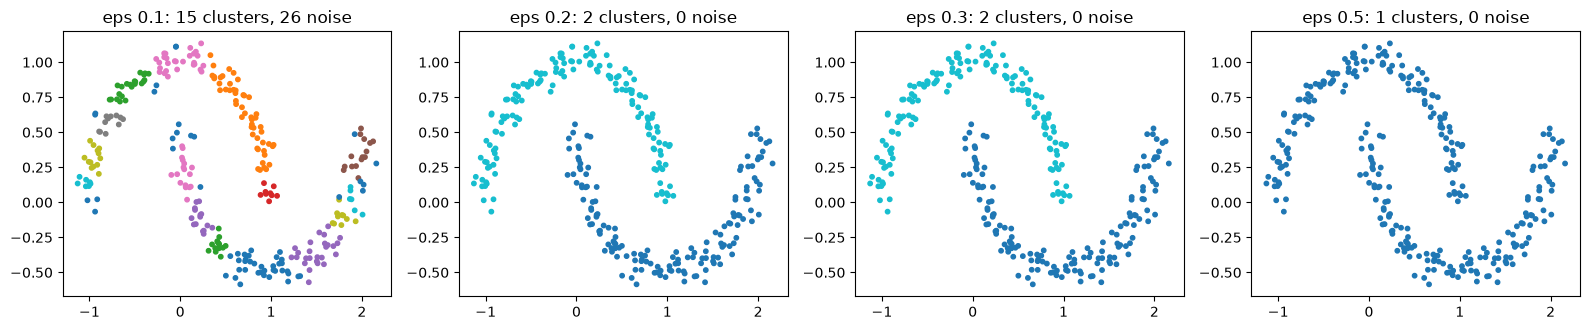

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, eps in zip(axes, [0.1, 0.2, 0.3, 0.5]):
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(moons)
    ax.scatter(moons[:, 0], moons[:, 1], c=lab, cmap="tab10", s=10)
    ax.set_title(f"eps {eps}: {lab.max() + 1} clusters, {(lab == -1).sum()} noise")
plt.tight_layout(); plt.show()

Too small (0.1): the crescents break into 15 fragments and 26 points become noise, because few points have 5 neighbours that close. Right (0.2 and 0.3): two clean crescents, no noise. Too large (0.5): the neighbourhoods reach across the gap between the crescents and everything merges into one cluster. There is usually a range of good values; the k-distance plot helps you find it. eps is the most important DBSCAN setting.

## Exercise 4

In [8]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

snapshot = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)    # 2011-12-10
rfm = sales.groupby("Customer ID").agg(
    recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"))
print(f"{len(sales):,} rows, {len(rfm):,} customers, snapshot {snapshot.date()}")

392,693 rows, 4,338 customers, snapshot 2011-12-10


In [9]:
from sklearn.preprocessing import StandardScaler

rfm_log = np.log1p(rfm)                         # tame the long right tails
X = StandardScaler().fit_transform(rfm_log)      # mean 0, std 1 per column
print("X shape:", X.shape)

X shape: (4338, 3)


In [10]:
from sklearn.mixture import GaussianMixture
gm = GaussianMixture(n_components=4, n_init=3, random_state=42).fit(X)
proba = gm.predict_proba(X)
out = rfm[["recency", "frequency", "monetary"]].assign(top=proba.max(axis=1), second=np.sort(proba, axis=1)[:, -2])
out.nsmallest(10, "top").round(2)

,recency,frequency,monetary,top,second
Customer ID,,,,,
14883.0,18,6,761.59,0.5,0.5
15862.0,8,4,832.88,0.5,0.5
15297.0,10,3,641.94,0.5,0.5
17988.0,11,7,201.12,0.5,0.5
15379.0,169,7,3703.29,0.5,0.5
14440.0,8,5,2357.68,0.5,0.5
14434.0,21,6,1372.80,0.5,0.5
15028.0,8,4,627.13,0.5,0.5
12472.0,32,7,6572.11,0.5,0.5


Their top two probabilities are both about 0.5: they sit exactly where two components overlap. Look at their order counts: all between 3 and 7, the range shared by the "moderate" component (3–7 orders) and the "heavy buyer" component (3 orders and up). Their spend and recency vary, so the model cannot tell whether they are moderate customers on a good run or heavy buyers who are just starting. A hard clustering would flip a coin for them; the mixture tells you it is a coin flip.